# 02. Operations: Volume, Backlog, Speed & Escalation Quality
**Input:** `data/processed/tickets_clean.csv`  
**Outputs:** Summary tables saved to `reports/tables/` and figures saved to `reports/figures/`

**Scope:**
- **Section C:** Volume & backlog dynamics (weekly created/closed/net backlog/EOW open, monthly category mix & growth drivers, active clients, Top 10/20 client share, channel & tier mix).
- **Section D:** First response & resolution speed (P50 & P90 across priority, category, escalation status, and handoffs; SLA attainment; open backlog age bands).
- **Section E:** Escalation quality (escalation rates, engineering outcomes, 57% avoidable baseline, return-to-L1 rate, handoff friction, resolution hour share, and duplicate-of-known-issue counts).

---
## C. Volume & Backlog Dynamics

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# Resolve paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TAB_DIR = PROJECT_ROOT / "reports" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Load clean dataset
df = pd.read_csv(PROCESSED_DIR / "tickets_clean.csv")
dt_cols = ["created_at", "first_response_at", "first_closed_at", "final_closed_at", "week_start"]
for col in dt_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

AS_OF_DATE = pd.Timestamp("2026-09-30 23:59:59")

# C1. Weekly Created, Closed, Net Backlog & End-of-Week Open Tickets
weeks = sorted(df["week_start"].unique())
weekly_rows = []
for w_start in weeks:
    w_end = w_start + pd.Timedelta(days=6, hours=23, minutes=59, seconds=59)
    eval_end = min(w_end, AS_OF_DATE)
    is_partial = int(df.loc[df["week_start"] == w_start, "is_partial_week"].iloc[0])

    created_cnt = ((df["created_at"] >= w_start) & (df["created_at"] <= eval_end)).sum()
    closed_cnt = ((df["final_closed_at"] >= w_start) & (df["final_closed_at"] <= eval_end)).sum()
    open_eow = (
        (df["created_at"] <= eval_end) &
        ((df["final_closed_at"].isna()) | (df["final_closed_at"] > eval_end))
    ).sum()

    weekly_rows.append({
        "week_start": w_start.strftime("%Y-%m-%d"),
        "is_partial_week": is_partial,
        "created": created_cnt,
        "closed": closed_cnt,
        "net_backlog": created_cnt - closed_cnt,
        "open_eow": open_eow
    })

weekly_vol = pd.DataFrame(weekly_rows)
weekly_vol.to_csv(TAB_DIR / "c1_weekly_volume_backlog.csv", index=False)
print("=== C1. WEEKLY VOLUME & BACKLOG (Flagged Partial Weeks: 2026-06-29 & 2026-09-28) ===")
display(weekly_vol)

# C2. Monthly Volume, Active Clients & Tickets per Client
monthly_vol = df.groupby("month").agg(
    tickets_created=("ticket_id", "count"),
    tickets_closed=("final_closed_at", lambda s: s.notna().sum()),
    unique_active_clients=("client_id", "nunique")
).reset_index()
monthly_vol["tickets_per_client"] = monthly_vol["tickets_created"] / monthly_vol["unique_active_clients"]
monthly_vol.to_csv(TAB_DIR / "c2_monthly_volume_clients.csv", index=False)
print("\n=== C2. MONTHLY VOLUME & ACTIVE CLIENTS ===")
display(monthly_vol)

# C3. Category Mix by Month & Contribution to Growth (Jul -> Sep)
cat_month = pd.crosstab(df["category"], df["month"])
cat_mix_pct = pd.crosstab(df["category"], df["month"], normalize="columns") * 100

total_growth = cat_month["2026-09"].sum() - cat_month["2026-07"].sum()
cat_growth = pd.DataFrame({
    "Jul_vol": cat_month["2026-07"],
    "Aug_vol": cat_month["2026-08"],
    "Sep_vol": cat_month["2026-09"],
    "Jul_mix_%": cat_mix_pct["2026-07"],
    "Aug_mix_%": cat_mix_pct["2026-08"],
    "Sep_mix_%": cat_mix_pct["2026-09"],
    "Jul_to_Sep_delta": cat_month["2026-09"] - cat_month["2026-07"],
    "pct_of_total_growth": ((cat_month["2026-09"] - cat_month["2026-07"]) / total_growth) * 100
}).sort_values("Jul_to_Sep_delta", ascending=False)

cat_growth.to_csv(TAB_DIR / "c3_category_mix_and_growth.csv")
print(f"\n=== C3. CATEGORY MIX & CONTRIBUTION TO GROWTH (Jul -> Sep Total Delta: +{total_growth} tickets) ===")
display(cat_growth)

# C4. Top 10 & Top 20 Client Share
client_vol = df.groupby(["client_id", "client_name", "client_tier"]).size().reset_index(name="tickets")
client_vol = client_vol.sort_values("tickets", ascending=False).reset_index(drop=True)
total_t = len(df)
print("\n=== C4. CLIENT CONCENTRATION ===")
print(f"Total unique clients: {len(client_vol)}")
print(f"Top 10 clients share: {client_vol.head(10)['tickets'].sum() / total_t * 100:.2f}% ({client_vol.head(10)['tickets'].sum()} / {total_t})")
print(f"Top 20 clients share: {client_vol.head(20)['tickets'].sum() / total_t * 100:.2f}% ({client_vol.head(20)['tickets'].sum()} / {total_t})")
display(client_vol.head(10))

# C5. Channel & Client Tier Mix
print("\n=== C5. CHANNEL & CLIENT TIER MIX ===")
for col in ["channel", "client_tier"]:
    mix = df[col].value_counts().to_frame("tickets")
    mix["share_%"] = mix["tickets"] / len(df) * 100
    display(mix)

=== C1. WEEKLY VOLUME & BACKLOG (Flagged Partial Weeks: 2026-06-29 & 2026-09-28) ===


,week_start,is_partial_week,created,closed,net_backlog,open_eow
0,2026-06-29,1,40,29,11,11
1,2026-07-06,0,87,86,1,12
2,2026-07-13,0,87,85,2,14
3,2026-07-20,0,97,87,10,24
4,2026-07-27,0,88,95,-7,17
5,2026-08-03,0,107,104,3,20
6,2026-08-10,0,103,99,4,24
7,2026-08-17,0,117,114,3,27
8,2026-08-24,0,114,120,-6,21
9,2026-08-31,0,105,88,17,38



=== C2. MONTHLY VOLUME & ACTIVE CLIENTS ===


,month,tickets_created,tickets_closed,unique_active_clients,tickets_per_client
0,2026-07,390,390,152,2.57
1,2026-08,462,462,149,3.10
2,2026-09,592,544,167,3.54



=== C3. CATEGORY MIX & CONTRIBUTION TO GROWTH (Jul -> Sep Total Delta: +202 tickets) ===


,Jul_vol,Aug_vol,Sep_vol,Jul_mix_%,Aug_mix_%,Sep_mix_%,Jul_to_Sep_delta,pct_of_total_growth
category,,,,,,,,
Cab delay / no-show complaint,29,46,72,7.44,9.96,12.16,43,21.29
Report export failing,57,59,90,14.62,12.77,15.20,33,16.34
Employee address / geocode change,13,23,39,3.33,4.98,6.59,26,12.87
Roster / booking not syncing,104,112,128,26.67,24.24,21.62,24,11.88
Billing / invoice discrepancy,24,22,42,6.15,4.76,7.09,18,8.91
Live tracking / GPS incorrect,65,80,83,16.67,17.32,14.02,18,8.91
How-to / feature request,23,43,38,5.90,9.31,6.42,15,7.43
Login / access issue,29,31,40,7.44,6.71,6.76,11,5.45
OTP / boarding issue,28,30,37,7.18,6.49,6.25,9,4.46



=== C4. CLIENT CONCENTRATION ===
Total unique clients: 191
Top 10 clients share: 18.28% (264 / 1444)
Top 20 clients share: 31.30% (452 / 1444)


,client_id,client_name,client_tier,tickets
0,CL-010,Meridian Labs,Enterprise,37
1,CL-034,Silverline Analytics,Enterprise,27
2,CL-060,Summit Financial,Enterprise,26
3,CL-153,Orion Financial,Enterprise,26
4,CL-114,Bluestone Financial,Enterprise,26
5,CL-098,Horizon Infotech,Enterprise,25
6,CL-175,Orion Health,Enterprise,25
7,CL-163,Crescent Solutions,Enterprise,24
8,CL-081,Harbor Tech Park,Enterprise,24
9,CL-088,Evergreen Systems,Enterprise,24



=== C5. CHANNEL & CLIENT TIER MIX ===


,tickets,share_%
channel,,
Email,553,38.30
Client portal,377,26.11
Phone,292,20.22
WhatsApp,222,15.37


,tickets,share_%
client_tier,,
Mid-market,656,45.43
Enterprise,614,42.52
SMB,174,12.05


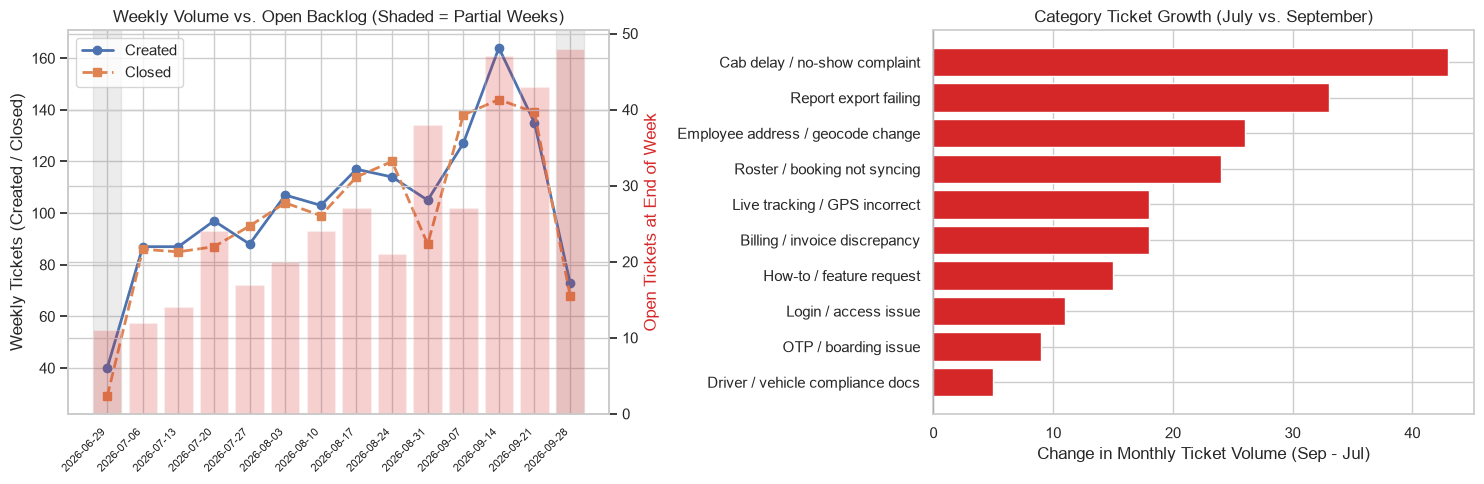

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Weekly Intake vs Closure & Open Backlog EOW (highlight partial weeks)
x = np.arange(len(weekly_vol))
axes[0].plot(x, weekly_vol["created"], marker="o", label="Created", linewidth=2)
axes[0].plot(x, weekly_vol["closed"], marker="s", label="Closed", linewidth=2, linestyle="--")
ax0_twin = axes[0].twinx()
ax0_twin.bar(x, weekly_vol["open_eow"], alpha=0.22, color="tab:red", label="Open Backlog (EOW)")

# Shade partial weeks
for idx, row in weekly_vol.iterrows():
    if row["is_partial_week"] == 1:
        axes[0].axvspan(idx - 0.4, idx + 0.4, color="gray", alpha=0.15)

axes[0].set_xticks(x)
axes[0].set_xticklabels(weekly_vol["week_start"], rotation=45, ha="right", fontsize=8)
axes[0].set_ylabel("Weekly Tickets (Created / Closed)")
ax0_twin.set_ylabel("Open Tickets at End of Week", color="tab:red")
axes[0].set_title("Weekly Volume vs. Open Backlog (Shaded = Partial Weeks)")
axes[0].legend(loc="upper left")

# Plot 2: Category Contribution to Jul -> Sep Volume Growth
growth_sorted = cat_growth.sort_values("Jul_to_Sep_delta", ascending=True)
colors = ["tab:red" if v > 0 else "tab:blue" for v in growth_sorted["Jul_to_Sep_delta"]]
axes[1].barh(growth_sorted.index, growth_sorted["Jul_to_Sep_delta"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Category Ticket Growth (July vs. September)")
axes[1].set_xlabel("Change in Monthly Ticket Volume (Sep - Jul)")

plt.tight_layout()
plt.savefig(FIG_DIR / "c_volume_and_backlog.png", dpi=150)
plt.show()

---
## D. Response & Resolution Speed
We compute **Median (P50)** and **90th Percentile (P90)** first response and resolution times across priorities, categories, escalation status, and engineering handoff counts, plus First-Response SLA attainment and open backlog age bands as of 30 Sep.

In [3]:
def p50_p90(group, col):
    s = group[col].dropna()
    return pd.Series({
        "n": int(len(s)),
        "median_hrs": s.median(),
        "p90_hrs": np.percentile(s, 90) if len(s) > 0 else np.nan
    })

# D1. First Response Speed: Overall & by Priority
d1_overall = p50_p90(df, "hrs_to_first_response").to_frame("Overall").T
d1_prio = df.groupby("priority").apply(p50_p90, col="hrs_to_first_response").sort_index()
d1_table = pd.concat([d1_overall, d1_prio])
d1_table.to_csv(TAB_DIR / "d1_first_response_speed.csv")
print("=== D1. FIRST RESPONSE SPEED (OVERALL & BY PRIORITY) ===")
display(d1_table)

# D2. Resolution Speed: Overall, Escalated vs Not, Category, and Handoff Count
d2_overall = p50_p90(df, "resolution_hrs").to_frame("Overall").T
d2_esc = df.groupby("is_escalated").apply(p50_p90, col="resolution_hrs")
d2_esc.index = ["Non-Escalated (L1 Only)", "Escalated to Eng"]

print("\n=== D2a. RESOLUTION SPEED (OVERALL & ESCALATED VS NOT) ===")
display(pd.concat([d2_overall, d2_esc]))

d2_cat = df.groupby("category").apply(p50_p90, col="resolution_hrs").sort_values("median_hrs", ascending=False)
d2_cat.to_csv(TAB_DIR / "d2_resolution_speed_by_category.csv")
print("\n=== D2b. RESOLUTION SPEED BY CATEGORY ===")
display(d2_cat)

d2_handoffs = df.groupby("eng_handoffs").apply(p50_p90, col="resolution_hrs").sort_index()
d2_handoffs.to_csv(TAB_DIR / "d2_resolution_speed_by_handoffs.csv")
print("\n=== D2c. RESOLUTION SPEED BY ENGINEERING HANDOFFS ===")
display(d2_handoffs)

# D3. First-Response SLA Attainment (Assumed Priority Targets: P1=1h, P2=4h, P3=8h, P4=24h)
SLA_TARGETS_HRS = {"P1": 1.0, "P2": 4.0, "P3": 8.0, "P4": 24.0}
df["frt_sla_target_hrs"] = df["priority"].map(SLA_TARGETS_HRS)
df["met_frt_sla"] = np.where(
    df["hrs_to_first_response"].notna(),
    (df["hrs_to_first_response"] <= df["frt_sla_target_hrs"]).astype(int),
    np.nan
)

d3_sla = df.groupby("priority").agg(
    sla_target_hrs=("frt_sla_target_hrs", "first"),
    responded_tickets=("met_frt_sla", "count"),
    within_sla_count=("met_frt_sla", "sum"),
    sla_attainment_pct=("met_frt_sla", lambda s: s.mean() * 100)
).sort_index()
d3_sla.to_csv(TAB_DIR / "d3_first_response_sla.csv")
print(f"\n=== D3. FIRST RESPONSE SLA ATTAINMENT (Overall: {df['met_frt_sla'].mean()*100:.2f}%) ===")
display(d3_sla)

# D4. Open Backlog Age Bands (as of 30 Sep 2026)
open_df = df[df["is_open"] == 1].copy()
d4_age = pd.DataFrame({
    "age_band": ["Open > 24 hours", "Open > 48 hours", "Open > 7 days (168h)"],
    "open_tickets": [
        (open_df["open_age_hrs"] > 24).sum(),
        (open_df["open_age_hrs"] > 48).sum(),
        (open_df["open_age_hrs"] > 168).sum()
    ]
})
d4_age["pct_of_48_open"] = d4_age["open_tickets"] / len(open_df) * 100
d4_age.to_csv(TAB_DIR / "d4_open_backlog_age_bands.csv", index=False)
print(f"\n=== D4. OPEN BACKLOG AGE BANDS (Total Open = {len(open_df)}, Status Breakdown: {open_df['status'].value_counts().to_dict()}) ===")
display(d4_age)

=== D1. FIRST RESPONSE SPEED (OVERALL & BY PRIORITY) ===


,n,median_hrs,p90_hrs
Overall,"1,439.00",2.58,11.29
P1,67.00,0.28,0.81
P2,264.00,1.05,3.48
P3,740.00,2.89,9.26
P4,368.00,6.11,21.66



=== D2a. RESOLUTION SPEED (OVERALL & ESCALATED VS NOT) ===


,n,median_hrs,p90_hrs
Overall,"1,396.00",22.31,120.92
Non-Escalated (L1 Only),944.00,12.57,43.33
Escalated to Eng,452.00,86.78,182.80



=== D2b. RESOLUTION SPEED BY CATEGORY ===


,n,median_hrs,p90_hrs
category,,,
Roster / booking not syncing,327.00,44.48,139.22
Live tracking / GPS incorrect,215.00,42.73,182.70
Billing / invoice discrepancy,85.00,39.62,121.27
Report export failing,201.00,23.87,102.20
Driver / vehicle compliance docs,55.00,20.30,54.62
OTP / boarding issue,92.00,18.50,114.17
Employee address / geocode change,73.00,17.93,64.68
Cab delay / no-show complaint,145.00,10.75,39.37
How-to / feature request,104.00,8.97,49.31


... (2 outputs left out)


=== D3. FIRST RESPONSE SLA ATTAINMENT (Overall: 89.44%) ===


,sla_target_hrs,responded_tickets,within_sla_count,sla_attainment_pct
priority,,,,
P1,1.00,67,65.00,97.01
P2,4.00,264,245.00,92.80
P3,8.00,740,637.00,86.08
P4,24.00,368,340.00,92.39



=== D4. OPEN BACKLOG AGE BANDS (Total Open = 48, Status Breakdown: {'Open - with L1': 29, 'Open - with Engineering': 19}) ===


,age_band,open_tickets,pct_of_48_open
0,Open > 24 hours,31,64.58
1,Open > 48 hours,25,52.08
2,Open > 7 days (168h),5,10.42


---
## E. Escalation Quality & Engineering Effort Waste
We measure overall, monthly, category, and agent escalation rates, engineering verdict breakdowns, avoidable escalation rates, L1 return rates, multi-handoff friction, resolution-hour consumption, and duplicate-of-known-issue concentrations.

In [4]:
esc_df = df[df["is_escalated"] == 1].copy()

print("=== E1. ESCALATION RATE OVERALL, BY MONTH, CATEGORY & AGENT ===")
print(f"Overall Escalation Rate: {df['is_escalated'].mean()*100:.2f}% ({len(esc_df)} / {len(df)})")

print("\nBy Month:")
display(df.groupby("month").agg(
    tickets=("ticket_id", "count"),
    escalated=("is_escalated", "sum"),
    esc_rate_pct=("is_escalated", lambda s: s.mean() * 100),
    avoidable_esc=("is_avoidable_esc", "sum"),
    avoidable_rate_of_esc_pct=("is_avoidable_esc", lambda s: s.sum() / max(df.loc[s.index, "is_escalated"].sum(), 1) * 100)
))

e1_cat = df.groupby("category").agg(
    tickets=("ticket_id", "count"),
    escalated=("is_escalated", "sum"),
    esc_rate_pct=("is_escalated", lambda s: s.mean() * 100),
    avoidable_esc=("is_avoidable_esc", "sum"),
    avoidable_rate_pct=("is_avoidable_esc", lambda s: s.sum() / max(df.loc[s.index, "is_escalated"].sum(), 1) * 100)
).sort_values("esc_rate_pct", ascending=False)
e1_cat.to_csv(TAB_DIR / "e1_escalation_by_category.csv")
print("\nBy Category:")
display(e1_cat)

print("\nBy Agent (Raw Rates - Case-Mix Adjusted in Notebook 3):")
display(df.groupby("assigned_agent").agg(
    tickets=("ticket_id", "count"),
    escalated=("is_escalated", "sum"),
    esc_rate_pct=("is_escalated", lambda s: s.mean() * 100),
    avoidable_rate_pct=("is_avoidable_esc", lambda s: s.sum() / max(df.loc[s.index, "is_escalated"].sum(), 1) * 100)
).sort_values("esc_rate_pct", ascending=False))

print("\n=== E2. ENGINEERING OUTCOME MIX (OVERALL & BY CATEGORY) ===")
e2_outcome = esc_df["eng_outcome"].value_counts().to_frame("tickets")
e2_outcome["share_of_esc_pct"] = e2_outcome["tickets"] / len(esc_df) * 100
display(e2_outcome)

e2_cat_outcome = pd.crosstab(esc_df["category"], esc_df["eng_outcome"])
e2_cat_outcome.to_csv(TAB_DIR / "e2_eng_outcome_by_category.csv")
display(e2_cat_outcome)

print("\n=== E3. AVOIDABLE ESCALATION, RETURN-TO-L1 & HANDOFF METRICS ===")
print(f"Avoidable Escalation Rate:      {esc_df['is_avoidable_esc'].mean()*100:.2f}% ({esc_df['is_avoidable_esc'].sum()} / {len(esc_df)})")
print(f"Returned-to-L1 Rate:            {esc_df['is_returned_to_l1'].mean()*100:.2f}% ({esc_df['is_returned_to_l1'].sum()} / {len(esc_df)})")
print(f"Avg Handoffs per Escalated Tkt: {esc_df['eng_handoffs'].mean():.2f}")
print(f"Share with 2+ Handoffs:         {(esc_df['eng_handoffs'] >= 2).mean()*100:.2f}% ({(esc_df['eng_handoffs'] >= 2).sum()} / {len(esc_df)})")

print("\n=== E4. RESOLUTION HOURS CONSUMED BY ESCALATIONS ===")
total_res_hrs = df["resolution_hrs"].sum()
esc_res_hrs = df.loc[df["is_escalated"] == 1, "resolution_hrs"].sum()
avoid_res_hrs = df.loc[df["is_avoidable_esc"] == 1, "resolution_hrs"].sum()
fixed_res_hrs = df.loc[(df["is_escalated"] == 1) & (df["is_avoidable_esc"] == 0), "resolution_hrs"].sum()

print(f"Total Resolution Hours (Closed Tickets): {total_res_hrs:,.1f} hrs")
print(f"Escalated Tickets Share:                 {esc_res_hrs / total_res_hrs * 100:.2f}% ({esc_res_hrs:,.1f} hrs)")
print(f"  - Avoidable Escalations Share:         {avoid_res_hrs / total_res_hrs * 100:.2f}% ({avoid_res_hrs:,.1f} hrs)")
print(f"  - Real-Fix Escalations Share:          {fixed_res_hrs / total_res_hrs * 100:.2f}% ({fixed_res_hrs:,.1f} hrs)")

print("\n=== E5. DUPLICATE-OF-KNOWN-ISSUE COUNTS BY CATEGORY ===")
dup_df = esc_df[esc_df["eng_outcome"] == "Duplicate of known issue"]
e5_dup = dup_df["category"].value_counts().reindex(df["category"].unique(), fill_value=0).to_frame("duplicate_count")
e5_dup["total_cat_escalations"] = esc_df["category"].value_counts()
e5_dup["pct_of_cat_escalations"] = (e5_dup["duplicate_count"] / e5_dup["total_cat_escalations"] * 100).fillna(0)
e5_dup = e5_dup.sort_values("duplicate_count", ascending=False)
e5_dup.to_csv(TAB_DIR / "e5_duplicate_issues_by_category.csv")
display(e5_dup)

=== E1. ESCALATION RATE OVERALL, BY MONTH, CATEGORY & AGENT ===
Overall Escalation Rate: 33.66% (486 / 1444)

By Month:


,tickets,escalated,esc_rate_pct,avoidable_esc,avoidable_rate_of_esc_pct
month,,,,,
2026-07,390,146,37.44,79,54.11
2026-08,462,151,32.68,85,56.29
2026-09,592,189,31.93,111,58.73



By Category:


,tickets,escalated,esc_rate_pct,avoidable_esc,avoidable_rate_pct
category,,,,,
Live tracking / GPS incorrect,228,127,55.70,67,52.76
Roster / booking not syncing,344,175,50.87,97,55.43
Report export failing,206,77,37.38,51,66.23
OTP / boarding issue,95,34,35.79,21,61.76
Billing / invoice discrepancy,88,26,29.55,13,50.00
Employee address / geocode change,75,11,14.67,6,54.55
How-to / feature request,104,12,11.54,9,75.00
Cab delay / no-show complaint,147,14,9.52,5,35.71
Login / access issue,100,8,8.00,5,62.50



By Agent (Raw Rates - Case-Mix Adjusted in Notebook 3):


,tickets,escalated,esc_rate_pct,avoidable_rate_pct
assigned_agent,,,,
Rahul T,151,93,61.59,75.27
Ananya R,189,76,40.21,47.37
Sneha M,176,61,34.66,49.18
Priya D,186,61,32.80,54.10
Arjun K,178,58,32.58,56.90
Vikram S,176,53,30.11,39.62
Neha P,171,49,28.65,61.22
Karan B,217,35,16.13,62.86



=== E2. ENGINEERING OUTCOME MIX (OVERALL & BY CATEGORY) ===


,tickets,share_of_esc_pct
eng_outcome,,
Fixed,211,43.42
Insufficient info - returned to L1,89,18.31
Config issue - returned to L1,84,17.28
Duplicate of known issue,56,11.52
Not a bug - how-to,24,4.94
Not reproducible,22,4.53


eng_outcome,Config issue - returned to L1,Duplicate of known issue,Fixed,Insufficient info - returned to L1,Not a bug - how-to,Not reproducible
category,,,,,,
Billing / invoice discrepancy,7,0,13,5,1,0
Cab delay / no-show complaint,3,0,9,2,0,0
Driver / vehicle compliance docs,0,0,1,1,0,0
Employee address / geocode change,1,0,5,4,0,1
How-to / feature request,4,1,3,2,2,0
Live tracking / GPS incorrect,21,7,60,24,8,7
Login / access issue,1,0,3,0,4,0
OTP / boarding issue,6,2,13,10,1,2
Report export failing,9,30,26,9,2,1



=== E3. AVOIDABLE ESCALATION, RETURN-TO-L1 & HANDOFF METRICS ===
Avoidable Escalation Rate:      56.58% (275 / 486)
Returned-to-L1 Rate:            35.60% (173 / 486)
Avg Handoffs per Escalated Tkt: 1.60
Share with 2+ Handoffs:         47.12% (229 / 486)

=== E4. RESOLUTION HOURS CONSUMED BY ESCALATIONS ===
Total Resolution Hours (Closed Tickets): 63,943.5 hrs
Escalated Tickets Share:                 70.54% (45,103.7 hrs)
  - Avoidable Escalations Share:         46.06% (29,453.6 hrs)
  - Real-Fix Escalations Share:          24.47% (15,650.1 hrs)

=== E5. DUPLICATE-OF-KNOWN-ISSUE COUNTS BY CATEGORY ===


,duplicate_count,total_cat_escalations,pct_of_cat_escalations
category,,,
Report export failing,30,77,38.96
Roster / booking not syncing,16,175,9.14
Live tracking / GPS incorrect,7,127,5.51
OTP / boarding issue,2,34,5.88
How-to / feature request,1,12,8.33
Login / access issue,0,8,0.00
Driver / vehicle compliance docs,0,2,0.00
Billing / invoice discrepancy,0,26,0.00
Cab delay / no-show complaint,0,14,0.00


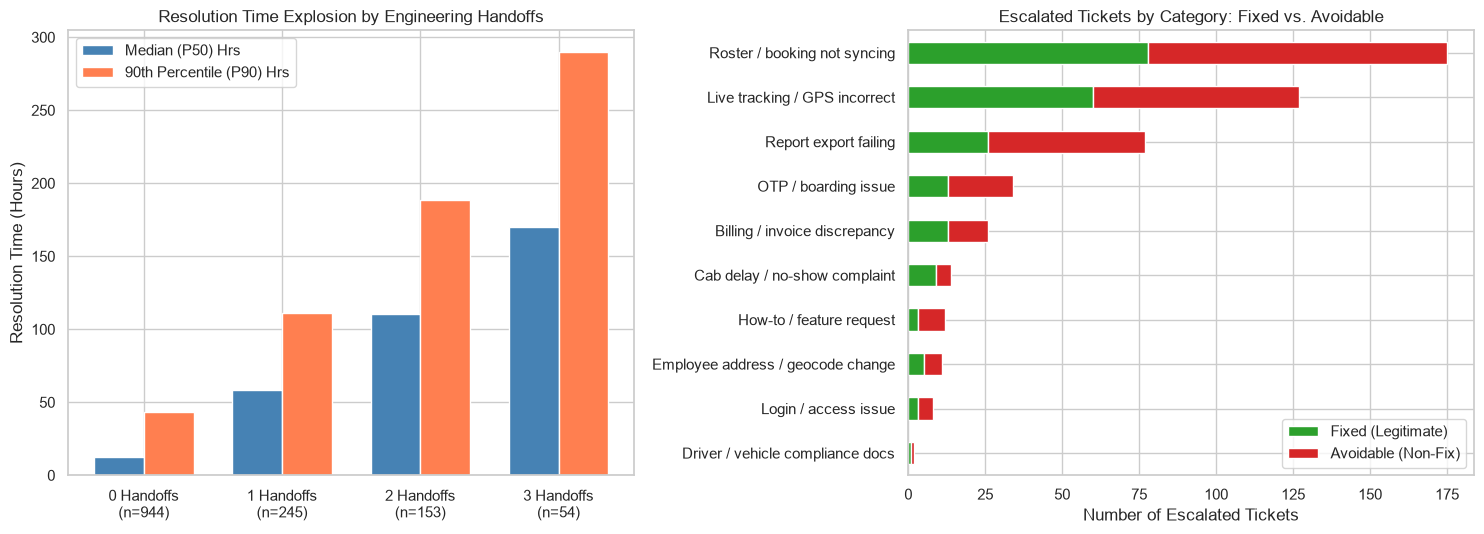

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Resolution Time (Median & P90) by Engineering Handoff Count
x_h = np.arange(len(d2_handoffs))
axes[0].bar(x_h - 0.18, d2_handoffs["median_hrs"], width=0.36, label="Median (P50) Hrs", color="steelblue")
axes[0].bar(x_h + 0.18, d2_handoffs["p90_hrs"], width=0.36, label="90th Percentile (P90) Hrs", color="coral")
axes[0].set_xticks(x_h)
axes[0].set_xticklabels([f"{int(h)} Handoffs\n(n={int(n)})" for h, n in zip(d2_handoffs.index, d2_handoffs["n"])])
axes[0].set_ylabel("Resolution Time (Hours)")
axes[0].set_title("Resolution Time Explosion by Engineering Handoffs")
axes[0].legend()

# Plot 2: Stacked Bar of Avoidable vs Real-Fix Escalations by Category
cat_esc_stack = esc_df.groupby(["category", "is_avoidable_esc"]).size().unstack(fill_value=0)
cat_esc_stack.columns = ["Fixed (Legitimate)", "Avoidable (Non-Fix)"]
cat_esc_stack = cat_esc_stack.loc[cat_esc_stack.sum(axis=1).sort_values(ascending=True).index]

cat_esc_stack.plot(kind="barh", stacked=True, ax=axes[1], color=["#2ca02c", "#d62728"])
axes[1].set_title("Escalated Tickets by Category: Fixed vs. Avoidable")
axes[1].set_xlabel("Number of Escalated Tickets")
axes[1].set_ylabel("")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "de_speed_and_escalations.png", dpi=150)
plt.show()